# rp2 Robustness: timing or re-levering under the expanding σ̄²

**Question: under the expanding reference σ̄²ᵢ,ₜ, is a managed portfolio's performance timing or
re-levering?** The main portfolios use a fixed σ̄²ᵢ, the mean over 2003-03 to 2008-02, so the only
thing that moves the weights is the forecast. The expanding reference, the mean from 2003-03
through month t, also moves over time: it rises after each crisis and re-levers every portfolio,
whatever the forecast. This notebook separates the two effects.

It reads the portfolios saved by `p1_build_portfolios.ipynb` (both specifications and the
re-levering control) and needs nothing from p2. p2 saves pair-test results for the expanding specification in `results/eval/pairs.csv`.

## Setup

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_checkout = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "models" / "research_config.py").is_file()),
    None,
)
if _checkout is None:
    raise FileNotFoundError("Start the notebook kernel from within this project checkout.")
sys.path.insert(0, str(_checkout / "models"))   # models/: research_config, portfolio.config and utils


from utils.portfolio_utils import (
    BH, CONTROL, PORTFOLIO_DIR,
    load_portfolios, performance_row, alpha_regression, alpha_vs_bh_and_control, pct_capped_pooled,
)


OUT_DIR = _checkout / "models" / "portfolio" / "robustness" / "results"
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.3f}".format)

In [2]:
run_info = json.loads((PORTFOLIO_DIR / "run_info.json").read_text())
MODELS, K_CAP = run_info["variants"], run_info["k_cap"]

portfolios = {}
for spec in ["fixed", "expanding"]:
    portfolios[spec], xret = load_portfolios(spec)
    assert set(MODELS) <= set(portfolios[spec]), f"{spec}: saved models do not match run_info"
assert CONTROL in portfolios["expanding"], "the control is missing; rerun p1"
TICKERS = list(xret.columns)
bh = xret.mean(axis=1)

sigma2_bar_fix = pd.read_csv(PORTFOLIO_DIR / "fixed" / "sigma2_bar.csv", index_col="date").iloc[0]
sigma2_bar_exp = pd.read_csv(PORTFOLIO_DIR / "expanding" / "sigma2_bar.csv", index_col="date", parse_dates=["date"])
print(f"Out-of-sample window: {run_info['oos_window'][0]} to {run_info['oos_window'][1]} ({len(xret)} months)")

Out-of-sample window: 2008-03 to 2025-12 (214 months)


## The expanding reference against the fixed one

σ̄²ᵢ,ₜ / σ̄²ᵢ,fixed per ETF. This ratio is the control's weight before the cap: it starts at 1 in
2008-03, when the expanding mean covers exactly the training window, and rises after each crisis.

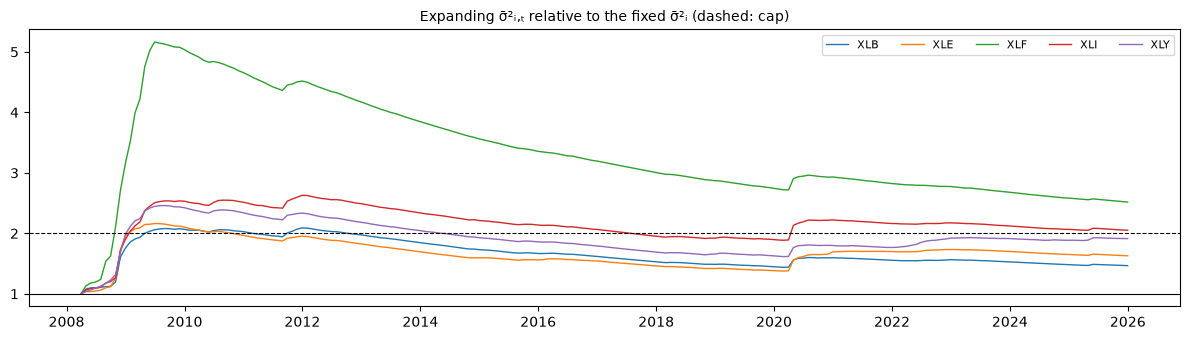

In [3]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ratio = sigma2_bar_exp / sigma2_bar_fix
for t in TICKERS:
    ax.plot(ratio.index, ratio[t], linewidth=1, label=t)
ax.axhline(1, color="black", linewidth=0.8)
ax.axhline(K_CAP, color="black", linestyle="--", linewidth=0.8)
ax.set_title("Expanding σ̄²ᵢ,ₜ relative to the fixed σ̄²ᵢ (dashed: cap)", fontsize=10)
ax.legend(ncol=5, fontsize=8)
fig.tight_layout()
plt.show()

## Timing or re-levering?

Under the expanding reference, a managed portfolio's performance mixes two things: the re-levering
that comes from σ̄²ᵢ,ₜ rising after crises, and the timing that comes from the forecast. The
**control** captures only the re-levering. It uses the same weight formula and cap, with the fixed
2003-03 to 2008-02 reference in place of σ̂² (the forecast variance):

w^ctrl_{i,t} = min(σ̄²ᵢ,ₜ / σ̄²ᵢ,fixed, 2).

It starts at 1 and rises only when the expanding mean rises. One regression per model, with
Newey-West standard errors:

f^σ_t = α + β_BH · BH_t + β_ctrl · control_t + εₜ.

**α is what the forecast adds beyond holding the ETFs and beyond re-levering.** For the control
row, α and β_BH come from a regression on BH alone; its fixed-specification entries are empty,
since under the fixed reference the control is identically buy-and-hold.

**% capped** under each specification shows how much of the expanding version is leverage: a
model at the cap far more often under the expanding reference is mostly being re-levered, not
timed.

In [4]:
def sharpe(res):
    return performance_row(res["managed"], res["bucket_weights"])["ann_sharpe"]


exp_res = portfolios["expanding"]
control = exp_res[CONTROL]

rows = {}
for m in MODELS:
    rows[m] = {
        "SR_fixed": sharpe(portfolios["fixed"][m]),
        "SR_expanding": sharpe(exp_res[m]),
        **alpha_vs_bh_and_control(exp_res[m], bh, control),
        "pct_capped_fixed": pct_capped_pooled(portfolios["fixed"][m]["weights_base"], K_CAP),
        "pct_capped_expanding": pct_capped_pooled(exp_res[m]["weights_base"], K_CAP),
    }

al = alpha_regression(control["managed"], bh.to_frame("BH"))
rows[CONTROL] = {
    "SR_fixed": np.nan,
    "SR_expanding": sharpe(control),
    "alpha_annual": al["alpha_annual"], "alpha_t": al["alpha_t"], "alpha_p": al["alpha_p"],
    "beta_BH": al["beta_BH"], "beta_control": np.nan, "R2": al["R2"],
    "pct_capped_fixed": np.nan,
    "pct_capped_expanding": pct_capped_pooled(control["weights_base"], K_CAP),
}

timing = pd.DataFrame(rows).T.rename_axis("portfolio")
timing = timing[["SR_fixed", "SR_expanding", "alpha_annual", "alpha_t", "alpha_p",
                 "beta_BH", "beta_control", "R2", "pct_capped_fixed", "pct_capped_expanding"]]
timing

,SR_fixed,SR_expanding,alpha_annual,alpha_t,alpha_p,beta_BH,beta_control,R2,pct_capped_fixed,pct_capped_expanding
portfolio,,,,,,,,,,
hist_rw,0.468,0.603,0.029,1.014,0.310,0.079,0.755,0.694,21.308,54.019
garch,0.497,0.608,0.027,1.017,0.309,-0.057,0.897,0.707,4.393,45.514
garch_midas_baa10y,0.499,0.610,0.027,1.019,0.308,-0.074,0.918,0.713,4.299,44.299
en_no_macro,0.453,0.592,0.028,1.012,0.311,0.259,0.587,0.713,5.327,36.729
en_no_vix,0.428,0.559,0.027,1.005,0.315,0.799,0.074,0.760,2.804,29.065
en_vix_only,0.459,0.567,0.022,0.793,0.428,0.125,0.713,0.701,2.243,36.168
en_full_macro,0.428,0.557,0.025,0.945,0.344,0.595,0.259,0.727,1.028,30.093
xgb_no_macro,0.467,0.595,0.034,1.247,0.212,0.653,0.200,0.727,2.430,32.243
xgb_no_vix,0.477,0.575,0.034,1.196,0.232,0.812,0.024,0.698,1.215,30.280


## Save

`results/rp2_timing_vs_relevering.csv`: the control regressions above.

In [5]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
timing.to_csv(OUT_DIR / "rp2_timing_vs_relevering.csv")
print("Saved to", (OUT_DIR / "rp2_timing_vs_relevering.csv").resolve())

Saved to C:\Documents\NUS\Y4S1\DSE4101\dse4101capstone_project\models\portfolio\robustness\results\rp2_timing_vs_relevering.csv
